# 42 · 가린 화소를 복원하는 표현

📎 **이번 질문** · 띠 무늬의 일부만 보여 주면 나머지 무늬를 맞히기 위해 어떤 특징을 배울까요?

준비물: 18 encoder–decoder, 19 patch·위치, 22 Autoencoder, [38 변형](38_augmentations.ipynb), 03·04 미분·Adam. NumPy·CPU float64만 사용하며 다른 노트북 실행 상태나 다운로드에 의존하지 않습니다. 띠의 방향과 촬영 조건을 단순화한 합성 자료로 수식부터 실제 학습까지 연결합니다.

| 표시 | 뜻 | 읽는 법 |
|---|---|---|
| 🔑 | 핵심 | 축과 기울기 경로를 씁니다 |
| 🔍 | 확인 | 그림·손계산·독립 평가를 대조합니다 |
| 📎 | 참고 | 처음 나온 용어·관용구를 풀이합니다 |
| ✏️ | 연습 | 한두 줄을 채우고 검사합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 가린 patch는 encoder에 들어가지 않고 위치가 있는 decoder가 원래 화소를 예측합니다.
2. 손실은 가린 화소 수로만 평균하며 입력 경로와 고정 복원 타깃 경로를 구분합니다.
3. mask 비율별로 실제 학습하고 같은 test mask의 복원과 동결 표현의 분류를 별도 평가합니다.

[학습 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/masked_reconstruction_plots.py)

In [1]:
# 준비 셀: 그림과 독립 미분 검산 도구입니다.
import sys
from pathlib import Path
import numpy as np
project_root = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient,rel_error
from src.utils.masked_reconstruction_plots import plot_panels,plot_curves,plot_points
setup_plots()

from src.utils.masked_reconstruction_plots import plot_images

## 🔑 1. 이미지를 patch로 나누고 일부 위치만 고릅니다

**이 절에서 가져갈 것:** mask는 원래 위치와 visible 원소의 대응을 함께 보존해야 합니다.

가로·세로 띠 무늬를8×8 작은 이미지로 그립니다. 2×2 조각16개 중 일부만 보여 주고 나머지를 가립니다. 띠의 방향 라벨은 복원 학습에 쓰지 않습니다.

> **용어**
> - **patch**는 연속한 화소를 잘라 만든 작은 조각입니다. 여기서는2×2=4화소입니다.
> - **mask**는 가린 위치를 나타내는 배열입니다. 여기서는 M=1이 가림,0이 보임입니다.
> - **visible token**은 encoder에 실제로 넣는 보이는 patch입니다. 가린 자리에0화소를 넣고 encode하는 것과 다릅니다.

이미지 `(N,8,8)`→patch $X:(N,P,Q)=(N,16,4)$입니다. P는 위에서 아래·왼쪽에서 오른쪽의 patch 위치, Q는 patch 안 행 우선 화소 순서입니다. $ids:(N,K)$는 각 이미지에서 고른 K개 visible 위치이며 같은 이미지 안에 중복이 없습니다. 원래 위치를 기억해야 복원 좌표를 알 수 있습니다.

> **코드** · reshape로 축을 `(N,H/2,2,W/2,2)`로 나누고 transpose로 patch위치 축을 먼저 모읍니다. `X[np.arange(N)[:,None],ids]`는 이미지마다 다른 위치를 선택합니다. `permutation(P)[:K]`는 중복 없는 K개 위치입니다.

In [2]:
small_image=np.arange(16.).reshape(1,4,4)/15
small_tokens=small_image.reshape(1,2,2,2,2).transpose(0,1,3,2,4).reshape(1,4,4)
small_mask=np.array([[0.,1.,1.,0.]])
small_masked=small_tokens*(1-small_mask[:,:,None])
small_shown=small_masked.reshape(1,2,2,2,2).transpose(0,1,3,2,4).reshape(1,4,4)

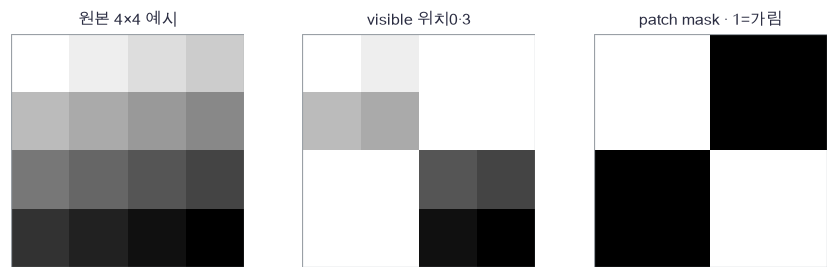

In [3]:
plot_images([small_image[0],small_shown[0],small_mask.reshape(2,2)],['원본 4×4 예시','visible 위치0·3','patch mask · 1=가림'])

🔍 **확인** · 가려진 조각의0은 그림 표시용입니다. 아래 encoder는 원본 배열에서 visible 위치0·3만 선택합니다.

In [4]:
def patchify(images,patch=2):
    """(N,H,W)를 행 우선 patch (N,P,Q)로 바꿉니다. H,W는 patch의 배수입니다."""
    n,h,w=images.shape
    assert h%patch==0, '높이는 patch 크기의 배수여야 합니다'
    assert w%patch==0, '너비는 patch 크기의 배수여야 합니다'
    return images.reshape(n,h//patch,patch,w//patch,patch).transpose(0,1,3,2,4).reshape(n,-1,patch*patch)

In [5]:
def unpatchify(tokens,height=8,width=8,patch=2):
    """patchify의 역순 transpose·reshape로 원래 화소를 복원합니다."""
    return tokens.reshape(len(tokens),height//patch,width//patch,patch,patch).transpose(0,1,3,2,4).reshape(len(tokens),height,width)

In [6]:
def sample_visible(n,patches,keep,rng):
    """각 이미지에서 keep개 위치를 비복원추출하고 나머지를 M=1로 둡니다."""
    assert 1<=keep<=patches, 'visible patch는 최소1개, 최대전체여야 합니다'
    ids=np.array([rng.permutation(patches)[:keep] for _ in range(n)])
    mask=np.ones((n,patches))
    mask[np.arange(n)[:,None],ids]=0.
    return ids,mask

In [7]:
# 쓰는 것: small_image (1절)
loop_tokens=[]
for r in [0,2]:
    for c in [0,2]:
        loop_tokens.append(small_image[0,r:r+2,c:c+2].ravel())
np.testing.assert_allclose(patchify(small_image)[0],loop_tokens)  # 검산: 반복문과 벡터화 patch 순서
np.testing.assert_allclose(patchify(small_image)[0,0],np.array([0.,1.,4.,5.])/15)  # 검산: 첫 patch 손계산
np.testing.assert_array_equal(unpatchify(patchify(small_image),4,4),small_image)  # 검산: patch 왕복
ids,mask=sample_visible(3,16,8,np.random.default_rng(426))
np.testing.assert_allclose(mask.sum(axis=1),8.)  # 검산: 이미지마다 정확히8개 가림
print('patch 순서·왕복·mask 개수를 확인했습니다.')

patch 순서·왕복·mask 개수를 확인했습니다.


### ✏️ 연습 1 · 이미지마다 다른 visible 위치

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

patch X:(N,P,Q)에서 ids:(N,K)를 고르세요.

In [8]:
def exercise_visible_gather(X,ids):
    """patch X:(N,P,Q)에서 ids:(N,K)를 고르세요."""

    ### 구현할 내용: patch X:(N,P,Q)에서 ids:(N,K)를 고르세요.
    raise NotImplementedError
    return visible

In [9]:
def check_visible_gather(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_array_equal(candidate(np.arange(12).reshape(2,3,2),np.array([[2,0],[1,2]])),[[[4,5],[0,1]],[[8,9],[10,11]]])  # 검산: 이미지별 두 위치
    print("연습 1: 독립 기준값과 일치합니다.")

run_check(check_visible_gather,exercise_visible_gather,hint="patch X:(N,P,Q)에서 ids:(N,K)를 고르세요.")

☐ exercise_visible_gather: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: patch X:(N,P,Q)에서 ids:(N,K)를 고르세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
visible = X[np.arange(len(X))[:,None],ids]
```

</details>

## 🔑 2. 보이는 조각을 인코딩하고 위치별로 복원합니다

**이 절에서 가져갈 것:** encoder에는 visible 화소만, decoder에는 context와 위치·mask 표식이 들어갑니다.

보이는 띠 조각에서 전체 방향과 위치에 관한 요약을 만듭니다. 이 노트북은 attention 대신 공유 tanh와 평균을 쓰는 **작은 masked autoencoder**입니다. MAE 원논문의 Transformer 전체 복제가 아닙니다.

> **용어** · **context** g는 visible 특징을 평균한 이미지별 요약입니다. **mask token** m은 가린 위치임을 decoder에 알려 주는 학습 벡터입니다. **위치 embedding** E,R은 patch 위치마다 다른 학습 벡터입니다.

$$h_{nk}=\tanh(X_{n,ids_{nk}}W+b+E_{ids_{nk}}),\quad g_n=K^{-1}\sum_kh_{nk},$$
$$r_{nj}=\tanh(g_nD+R_j+M_{nj}m),\quad \hat X_{nj}=r_{nj}O+c.$$

$W:(Q,H)$, $E,R:(P,H)$, $D:(H,H)$, $m,b:(H,)$, $O:(H,Q)$, $c:(Q,)$입니다. decoder는 P개 위치 모두에 값을 내지만 다음 절 손실은 가린 위치만 씁니다. visible이0개이면 평균을 정의하지 않으므로 거부합니다. 모두 보이는 경우 encoder는 동작하며 복원 손실은 별도 규약을 따릅니다.

In [10]:
# 쓰는 것: small_tokens (1절)
demo_visible=small_tokens[:,[0,3],:]
demo_position=np.array([[[.1,-.1],[-.1,.1]]])
demo_h=np.tanh(demo_visible@np.full((4,2),.2)+demo_position)
demo_g=demo_h.mean(axis=1)
demo_r=np.tanh(demo_g[:,None,:]+np.array([[[0.,0.],[.1,0.],[0.,.1],[.1,.1]]]))

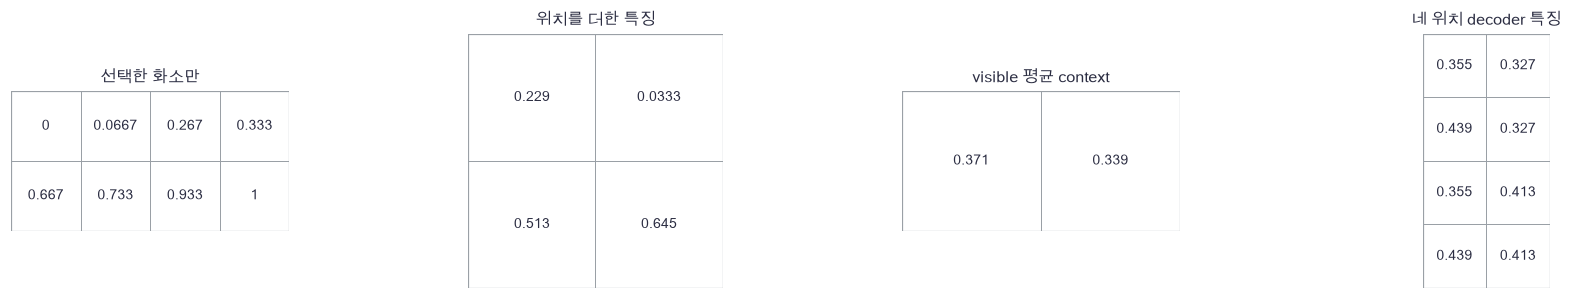

In [11]:
plot_panels([demo_visible[0],demo_h[0],demo_g,demo_r[0]],['선택한 화소만','위치를 더한 특징','visible 평균 context','네 위치 decoder 특징'])

🔍 **확인** · 작은 그림은 mask token을0으로 놓은 직접 계산입니다. 위치가 없으면 같은 context를 받은 모든 복원 조각이 같아질 수 있습니다.

In [12]:
def init_masked(seed=420,patches=16,pixels=4,hidden=8):
    """visible encoder·위치·mask token·decoder의 모든 배열을 초기화합니다."""
    rng=np.random.default_rng(seed)
    return {'W':rng.normal(0,.2,(pixels,hidden)),'b':np.zeros(hidden),
            'E':rng.normal(0,.1,(patches,hidden)),'D':rng.normal(0,.2,(hidden,hidden)),
            'R':rng.normal(0,.1,(patches,hidden)),'m':np.zeros(hidden),
            'O':rng.normal(0,.2,(hidden,pixels)),'c':np.zeros(pixels)}

In [13]:
def masked_forward(X,ids,mask,p):
    """visible patch만 encode하고 context·위치·mask token으로 전체 patch를 예측합니다."""
    assert ids.shape[1]>0, 'visible patch가 최소1개 있어야 합니다'
    visible=X[np.arange(len(X))[:,None],ids]
    H=np.tanh(visible@p['W']+p['b']+p['E'][ids])
    context=H.mean(axis=1)
    decoder=np.tanh((context@p['D'])[:,None,:]+p['R'][None,:,:]+mask[:,:,None]*p['m'])
    prediction=decoder@p['O']+p['c']
    return prediction,(X.shape,ids,mask,visible,H,context,decoder)

In [14]:
# 쓰는 것: small_mask (1절) · small_tokens (1절)
small_params=init_masked(427,patches=4,pixels=4,hidden=2)
small_ids=np.array([[0,3]])
small_prediction,small_cache=masked_forward(small_tokens,small_ids,small_mask,small_params)
changed=small_tokens.copy()
changed[small_mask.astype(bool)]+=100.
changed_prediction,_=masked_forward(changed,small_ids,small_mask,small_params)
np.testing.assert_array_equal(changed_prediction,small_prediction)  # 검산: 가린 입력 화소를 바꾸어도 예측 불변
permuted_prediction,_=masked_forward(small_tokens,small_ids[:,::-1],small_mask,small_params)
np.testing.assert_allclose(permuted_prediction,small_prediction)  # 검산: 위치를 보존한 visible 목록 순서 불변
print('masked 입력 누출이 없고 visible 목록 순서는 무관합니다.')
try:
    masked_forward(small_tokens,np.empty((1,0),dtype=int),np.ones((1,4)),small_params)
except AssertionError:
    print("빈 visible ids는 forward에서도 거부합니다.")
else:
    raise AssertionError("빈 visible 입력은 거부되어야 합니다")

masked 입력 누출이 없고 visible 목록 순서는 무관합니다.
빈 visible ids는 forward에서도 거부합니다.


### ✏️ 연습 2 · visible 개수로 평균하기

visible 특징 H:(N,K,D)의 K축만 평균하세요.

In [15]:
def exercise_visible_pool(H):
    """visible 특징 H:(N,K,D)의 K축만 평균하세요."""

    ### 구현할 내용: visible 특징 H:(N,K,D)의 K축만 평균하세요.
    raise NotImplementedError
    return context

In [16]:
def check_visible_pool(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[[1.,2.],[3.,4.],[5.,6.]]])),[[3.,4.]])  # 검산: K=3 평균
    print("연습 2: 독립 기준값과 일치합니다.")

run_check(check_visible_pool,exercise_visible_pool,hint="visible 특징 H:(N,K,D)의 K축만 평균하세요.")

☐ exercise_visible_pool: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: visible 특징 H:(N,K,D)의 K축만 평균하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
context = H.mean(axis=1)
```

</details>

## 🔑 3. 가린 화소 수로만 오차를 평균합니다

**이 절에서 가져갈 것:** 보여 준 화소의 쉬운 복사 점수가 가린 부분 평가를 희석하지 않게 합니다.

예측하지 않아도 이미 보이는 화소를 전체 손실에 넣으면 mask 비율마다 숫자의 의미가 달라집니다. 여기서는 가린 화소만 계산합니다.

$$C=Q\sum_{n,j}M_{nj},\quad L=\frac{1}{2C}\sum_{n,j,q}M_{nj}(\hat X_{njq}-X_{njq})^2,$$
$$d\hat X_{njq}=M_{nj}(\hat X_{njq}-X_{njq})/C.$$

이는 **가린 화소 단위 평균의 반 제곱오차**입니다. mask가 비어 C=0이면 loss와기울기0을 반환합니다. 이때 평가할 화소가 없는 것이므로 완벽한 복원으로 해석하지 않습니다. 모든 이미지의 K가 같아 이미지별 가중치도 같습니다. 서로 다른 K를 섞으면 더 많이 가린 이미지의 가중치가 커지는 전역 화소 평균입니다.

타깃 X는 정답 배열로 고정하고 모델 입력 경로만 미분합니다. 같은 X를 입력과 타깃으로 묶어 수치미분하면 타깃을 움직인 직접 경로 −d예측도 추가됩니다. 아래 전체 모델 검산은 타깃을 별도 복사해 이 혼동을 피합니다.

In [17]:
loss_target=np.array([[[1.,2.],[3.,4.],[5.,6.]]])
loss_pred=np.array([[[99.,99.],[4.,6.],[99.,99.]]])
loss_mask=np.array([[0.,1.,0.]])
masked_residual=(loss_pred-loss_target)*loss_mask[:,:,None]
hand_grad=masked_residual/2

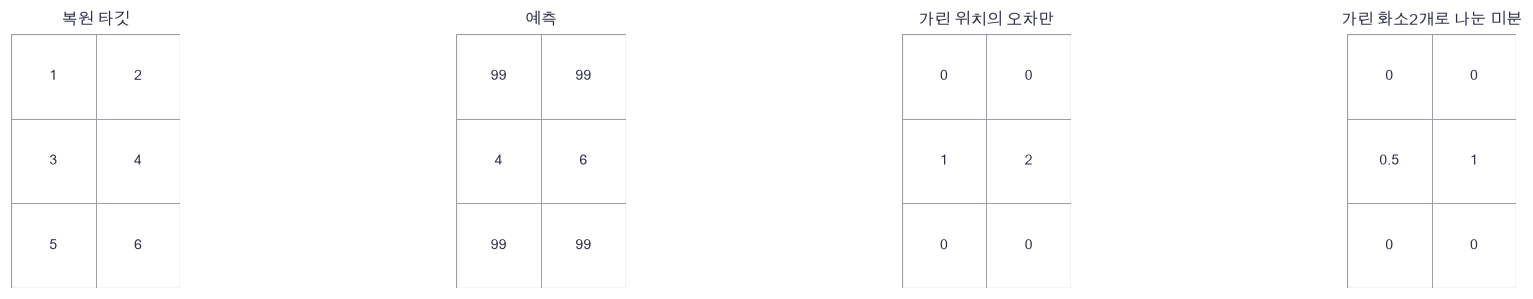

In [18]:
plot_panels([loss_target[0],loss_pred[0],masked_residual[0],hand_grad[0]],['복원 타깃','예측','가린 위치의 오차만','가린 화소2개로 나눈 미분'])

🔍 **확인** · 보여 준 위치의 예측99는 이 손실에 영향을 주지 않습니다. 가린 두 화소의 오차1·2에서 loss=(1+4)/(2×2)=1.25입니다.

In [19]:
def masked_loss(prediction,target,mask):
    """가린 화소만 반 제곱오차 평균. 빈 mask이면 손실·미분0으로 정합니다."""
    count=mask.sum()*prediction.shape[-1]
    if count==0:
        return 0.,np.zeros_like(prediction)
    residual=prediction-target
    gradient=residual*mask[:,:,None]/count
    return .5*np.sum(residual**2*mask[:,:,None])/count,gradient

In [20]:
loss,G=masked_loss(loss_pred,loss_target,loss_mask)
np.testing.assert_allclose(loss,1.25)  # 검산: 손계산 분모
np.testing.assert_allclose(G,hand_grad)  # 검산: 그림 계산 = 구현
zero_loss,zero_G=masked_loss(loss_pred,loss_target,np.zeros_like(loss_mask))
np.testing.assert_allclose(zero_loss,0.)  # 검산: 평가 위치가 없을 때 규약0
np.testing.assert_allclose(zero_G,0.)  # 검산: 빈 mask 기울기0
print('masked-only 분모와 빈 mask 규약을 확인했습니다.')

masked-only 분모와 빈 mask 규약을 확인했습니다.


### ✏️ 연습 3 · 오차의 실제 화소 분모

가린 patch 수에 patch당 화소 수 Q를 곱하세요.

In [21]:
def exercise_masked_denominator(mask,Q):
    """가린 patch 수에 patch당 화소 수 Q를 곱하세요."""

    ### 구현할 내용: 가린 patch 수에 patch당 화소 수 Q를 곱하세요.
    raise NotImplementedError
    return count

In [22]:
def check_masked_denominator(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.,0.,1.],[0.,1.,0.]]),4),12.)  # 검산: 세 patch×네 화소
    print("연습 3: 독립 기준값과 일치합니다.")

run_check(check_masked_denominator,exercise_masked_denominator,hint="가린 patch 수에 patch당 화소 수 Q를 곱하세요.")

☐ exercise_masked_denominator: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 가린 patch 수에 patch당 화소 수 Q를 곱하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
count = mask.sum()*Q
```

</details>

## 🔑 4. 위치 선택을 거슬러 전체 미분을 검산합니다

**이 절에서 가져갈 것:** gather의 역방향은 원래 위치에 기울기를 누적하는 scatter입니다.

같은 patch 위치의 E는 여러 이미지에서 공유됩니다. 각 이미지가 만든 기여를 그 위치에 더해야 합니다.

> **용어** · **scatter-add**는 선택했던 원래 인덱스 위치로 값을 되돌려 더하는 연산입니다. **상류 기울기** G는 여기서 손실이 준 d예측입니다.

$dO=\sum_{n,j}r_{nj}^TG_{nj}$, $dc=\sum_{n,j}G_{nj}$, $dU=(GO^T)\odot(1-r^2)$, $a_n=\sum_jdU_{nj}$입니다. $dD=g^Ta$, $dR_j=\sum_ndU_{nj}$, $dm=\sum_{n,j}M_{nj}dU_{nj}$, $dg=aD^T$를 얻습니다. visible에 $dh=dg/K$를 나누고 $dA=dh\odot(1-h^2)$, $dW=\sum X_v^TdA$, $db=\sum dA$를 계산합니다. $dE$와 $dX$는 ids에 누적합니다. 가린 X의 **모델 입력 경로** 기울기는0입니다.

> **코드** · `np.add.at(array,ids,values)`는 ids가 여러 번 나타나도 모든 값을 누적합니다. `array[ids] += values`는 중복 인덱스에서 같은 의미를 보장하지 않습니다. `reshape(-1,H)`는 관측·patch 축을 하나로 모아 행렬곱합니다.

In [23]:
scatter_ids=np.array([[0,2],[2,3]])
scatter_values=np.array([[[1.],[2.]],[[3.],[4.]]])
scatter_result=np.zeros((4,1))
np.add.at(scatter_result,scatter_ids,scatter_values)
mean_upstream=np.array([[6.,3.]])
mean_distributed=np.repeat(mean_upstream[:,None,:]/3,3,axis=1)

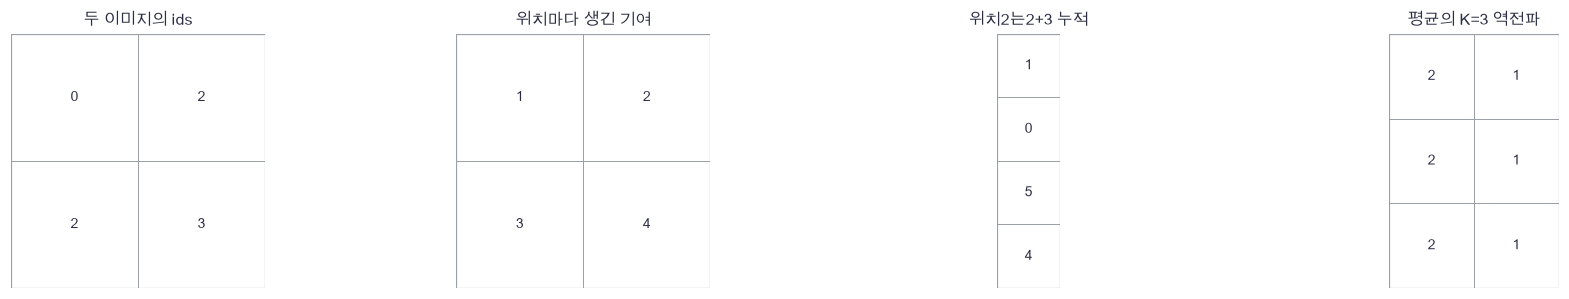

In [24]:
plot_panels([scatter_ids,scatter_values.reshape(2,2),scatter_result,mean_distributed[0]],['두 이미지의 ids','위치마다 생긴 기여','위치2는2+3 누적','평균의 K=3 역전파'])

🔍 **확인** · 위치2는 두 이미지에서 쓰여 기울기가5입니다. 원래 위치0·1·2·3 순서로 결과를 읽습니다.

In [25]:
def masked_backward(G,cache,p):
    """decoder·풀링·gather를 거꾸로 따라 모든 파라미터와 입력을 미분합니다."""
    # 1. 출력과 위치·mask token의 모든 관측·patch 기여를 더합니다.
    shape,ids,mask,visible,H,context,decoder=cache
    n,k,h=H.shape
    dU=(G@p['O'].T)*(1-decoder**2)
    pooled=dU.sum(axis=1)
    grads={'O':decoder.reshape(-1,h).T@G.reshape(-1,G.shape[-1]),'c':G.sum(axis=(0,1)),
           'D':context.T@pooled,'R':dU.sum(axis=0),'m':(dU*mask[:,:,None]).sum(axis=(0,1))}
    # 2. 평균 context를 visible 원소에 나누고 위치 인덱스로 누적합니다.
    dH=np.repeat((pooled@p['D'].T)[:,None,:]/k,k,axis=1)
    dA=dH*(1-H**2)
    grads['W']=visible.reshape(-1,visible.shape[-1]).T@dA.reshape(-1,h)
    grads['b']=dA.sum(axis=(0,1))
    grads['E']=np.zeros_like(p['E'])
    np.add.at(grads['E'],ids,dA)
    dX=np.zeros(shape)
    np.add.at(dX,(np.arange(n)[:,None],ids),dA@p['W'].T)
    return grads,dX

In [26]:
# 쓰는 것: init_masked (2절) · masked_forward (2절) · masked_loss (3절)
probe=init_masked(428,patches=4,pixels=1,hidden=2)
probe_x=np.random.default_rng(429).normal(size=(2,4,1))
probe_target=probe_x.copy()
probe_ids=np.array([[0,2],[1,2]])
probe_mask=np.ones((2,4))
probe_mask[np.arange(2)[:,None],probe_ids]=0.
probe_prediction,probe_cache=masked_forward(probe_x,probe_ids,probe_mask,probe)
_,probe_g=masked_loss(probe_prediction,probe_target,probe_mask)
analytic,analytic_x=masked_backward(probe_g,probe_cache,probe)

In [27]:
def full_objective():
    """고정 mask·고정 타깃에서 모델의 모든 경로를 미분합니다."""
    # 쓰는 것: masked_forward (2절) · masked_loss (3절)
    prediction,_=masked_forward(probe_x,probe_ids,probe_mask,probe)
    return masked_loss(prediction,probe_target,probe_mask)[0]

In [28]:
errors=[]
for key in probe:
    numeric=numerical_gradient(full_objective,probe[key])
    np.testing.assert_allclose(analytic[key],numeric,atol=2e-8,rtol=3e-5)  # 검산: 위치·mask token 포함 모든 파라미터
    errors.append(np.max(np.abs(analytic[key]-numeric)))
numeric_x=numerical_gradient(full_objective,probe_x)
np.testing.assert_allclose(analytic_x,numeric_x,atol=2e-8,rtol=3e-5)  # 검산: 모든 입력 원소
np.testing.assert_array_equal(analytic_x[probe_mask.astype(bool)],0.)  # 검산: masked 입력 경로0
print('전체 미분 최대 절대오차',max(errors+[np.max(np.abs(analytic_x-numeric_x))]))

전체 미분 최대 절대오차 3.973459755668429e-11


### ✏️ 연습 4 · visible 입력의 기울기 위치

visible 기울기 g:(N,K,Q)를 원래 patch 위치로 더하세요.

In [29]:
def exercise_masked_input_gradient(shape,ids,g):
    """visible 기울기 g:(N,K,Q)를 원래 patch 위치로 더하세요."""
    result = np.zeros(shape)
    ### 구현할 내용: visible 기울기 g:(N,K,Q)를 원래 patch 위치로 더하세요.
    raise NotImplementedError
    return result

In [30]:
def check_masked_input_gradient(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_array_equal(candidate((1,3,1),np.array([[0,2]]),np.array([[[2.],[5.]]])),[[[2.],[0.],[5.]]])  # 검산: 가린 위치1은0
    print("연습 4: 독립 기준값과 일치합니다.")

run_check(check_masked_input_gradient,exercise_masked_input_gradient,hint="visible 기울기 g:(N,K,Q)를 원래 patch 위치로 더하세요.")

☐ exercise_masked_input_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: visible 기울기 g:(N,K,Q)를 원래 patch 위치로 더하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
np.add.at(result,(np.arange(shape[0])[:,None],ids),g)
```

</details>

## 🔑 5. mask 비율과 복원·표현 평가를 분리합니다

**이 절에서 가져갈 것:** 가린 부분 복원과 분류에 쓸 표현의 유용성을 각각 독립 평가합니다.

8×8 이미지의 띠 중심·밝기·작은 센서 잡음을 매번 바꿉니다. train256/valid64/test128(seed421/422/423)을 독립 생성합니다. 방향 라벨은 선형 probe에만 사용합니다. 이미지 통계로 test를 정규화하지 않습니다.

고정 계획: 초기420, visible K12/8/4 즉 mask25/50/75%, 동일 batch난수424·mask난수425,500갱신·batch32·Adam lr.005. Adam의 .9/.999 모멘트를 bias 보정합니다. 세 조건의 validation은 **같은 K8 mask(seed430)**, test도 같은 K8 mask(seed431)입니다. validation은 관찰만 하고 선택하지 않습니다. test를 보고 설정을 바꾸지 않습니다. train의 평균 이미지를 복사하는 무학습 기준선도 같은 test mask에서 평가합니다.

표현 평가는 모든 patch를 보인 encoder 평균 g를 사용합니다. 학습 때 일부만 보인 것과 입력 조건이 다름을 명시합니다. decoder는 쓰지 않고, 각 encoder를 동결한 뒤 train256개 방향 라벨로2클래스 선형 probe를300전배치 SGD lr.15로 학습합니다. CE미분 `(P-onehot)/N`, `g.T@G`이며 test분모128입니다. probe는0초기화하고 encoder 통계의 평균·분산도 보고합니다. 한 seed의 교육용 비교이므로 특정 mask 비율의 우위를 일반화하지 않습니다.

> **코드** · `np.mgrid`는 모든 화소의 행·열 좌표를 만듭니다. `np.where`는 라벨에 따라 가로·세로 좌표를 고릅니다. `clip`은 화소를0–1로 제한합니다. `integers`는 배치 복원추출이며 train에서만 사용합니다.

In [31]:
preview_row,preview_col=np.mgrid[:8,:8]
vertical=.05+.8*np.exp(-.5*((preview_col-3.)/.9)**2)
horizontal=.05+.8*np.exp(-.5*((preview_row-4.)/.9)**2)
preview_mask=np.tile(np.array([0.,1.,0.,1.]),(4,1))
mask_pixels=np.repeat(np.repeat(preview_mask,2,axis=0),2,axis=1)

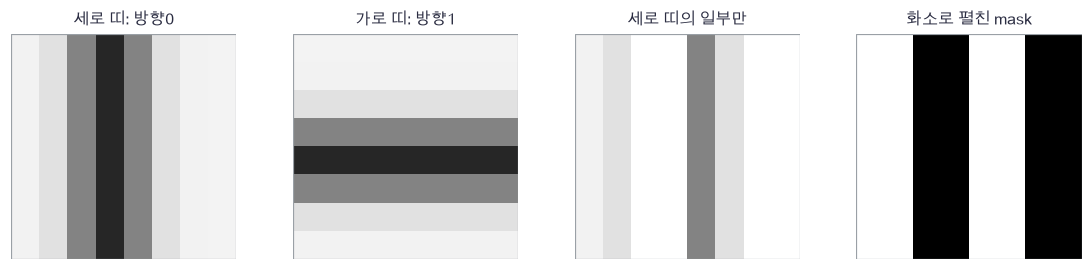

In [32]:
plot_images([vertical,horizontal,vertical*(1-mask_pixels),mask_pixels],['세로 띠: 방향0','가로 띠: 방향1','세로 띠의 일부만','화소로 펼친 mask'])

🔍 **확인** · 띠의 방향을 구별하는 라벨은 복원 목적에 전달하지 않습니다. 원본 화소를 맞히는 자기지도 목표와 나중의 방향 분류를 구분합니다.

In [33]:
def make_images(n,seed):
    """가로·세로의 매끄러운 띠 이미지를 생성합니다. (N,8,8), orientation:(N,)."""
    rng=np.random.default_rng(seed)
    labels=rng.integers(0,2,n)
    center=rng.uniform(2.,5.,n)
    intensity=rng.uniform(.5,.9,n)
    row,col=np.mgrid[:8,:8]
    coord=np.where(labels[:,None,None]==0,col[None,:,:],row[None,:,:])
    images=.05+intensity[:,None,None]*np.exp(-.5*((coord-center[:,None,None])/.9)**2)
    images+=rng.normal(0,.015,images.shape)
    return np.clip(images,0.,1.),labels

In [34]:
def adam_step(p,g,m,v,step,lr=.01):
    """Adam 모멘트·bias 보정을 적용합니다."""
    for k in p:
        m[k]=.9*m[k]+.1*g[k]
        v[k]=.999*v[k]+.001*g[k]**2
        p[k]-=lr*(m[k]/(1-.9**step))/(np.sqrt(v[k]/(1-.999**step))+1e-8)

In [35]:
def train_masked(X,valid_X,valid_ids,valid_mask,initial,keep):
    """visible 수만 다른 조건을 같은 초기·500갱신으로 학습합니다."""
    # 쓰는 것: masked_backward (4절) · masked_forward (2절) · masked_loss (3절) · sample_visible (1절)
    # 1. 각 조건의 배열·optimizer·배치·mask 난수를 분리합니다.
    p={k:a.copy() for k,a in initial.items()}
    m={k:np.zeros_like(a) for k,a in p.items()}
    v={k:np.zeros_like(a) for k,a in p.items()}
    batch_rng=np.random.default_rng(424)
    mask_rng=np.random.default_rng(425)
    history=[]
    # 2. 오직 masked 화소 오차를 미분합니다.
    for step in range(1,501):
        idx=batch_rng.integers(0,len(X),32)
        ids,mask=sample_visible(32,X.shape[1],keep,mask_rng)
        prediction,cache=masked_forward(X[idx],ids,mask,p)
        loss,G=masked_loss(prediction,X[idx],mask)
        grads,_=masked_backward(G,cache,p)
        adam_step(p,grads,m,v,step,lr=.005)
        if step%50==0:
            estimate,_=masked_forward(valid_X,valid_ids,valid_mask,p)
            history.append([step,masked_loss(estimate,valid_X,valid_mask)[0]])
    return p,np.array(history)

In [36]:
def all_visible_features(X,p):
    """평가용 encoder의 모든 patch 평균. decoder·mask token은 사용하지 않습니다."""
    H=np.tanh(X@p['W']+p['b']+p['E'][None,:,:])
    return H.mean(axis=1)

In [37]:
def multiclass_loss(logits,y):
    """안정적인 표본 평균 CE와 logit 미분. (N,C), (N,) → scalar,(N,C)."""
    shifted=logits-logits.max(axis=1,keepdims=True)
    expS=np.exp(shifted)
    P=expS/expS.sum(axis=1,keepdims=True)
    loss=np.mean(np.log(expS.sum(axis=1))-shifted[np.arange(len(y)),y])
    G=P.copy()
    G[np.arange(len(y)),y]-=1
    return loss,G/len(y)

In [38]:
def fit_probe(features,y):
    """고정 표현 위의 선형 2클래스 probe만 300회 전배치 SGD 학습합니다."""
    W=np.zeros((features.shape[1],2))
    b=np.zeros(2)
    for step in range(300):
        loss,G=multiclass_loss(features@W+b,y)
        W-=.15*features.T@G
        b-=.15*G.sum(axis=0)
    return W,b

In [39]:
# 쓰는 것: init_masked (2절) · make_images (5절) · patchify (1절) · sample_visible (1절) · train_masked (5절)
train_images,train_y=make_images(256,421)
valid_images,valid_y=make_images(64,422)
test_images,test_y=make_images(128,423)
train_x=patchify(train_images)
valid_x=patchify(valid_images)
test_x=patchify(test_images)
valid_ids,valid_mask=sample_visible(64,16,8,np.random.default_rng(430))
test_ids,test_mask=sample_visible(128,16,8,np.random.default_rng(431))
initial=init_masked()
keeps=[12,8,4]
models=[]
histories=[]
for keep in keeps:
    fitted,history=train_masked(train_x,valid_x,valid_ids,valid_mask,initial,keep)
    models.append(fitted)
    histories.append(history)
print('각 모델 파라미터',sum(a.size for a in initial.values()),'· 500갱신')

각 모델 파라미터 404 · 500갱신


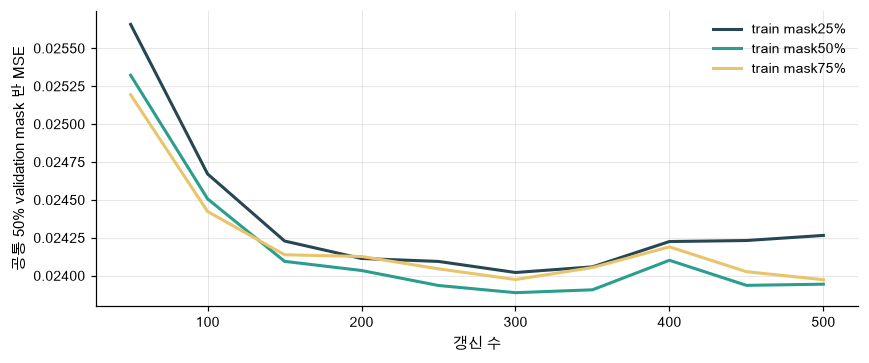

In [40]:
plot_curves(histories,['train mask25%','train mask50%','train mask75%'],'공통 50% validation mask 반 MSE')

In [41]:
# 쓰는 것: all_visible_features (5절) · masked_forward (2절) · masked_loss (3절)
baseline=np.repeat(train_x.mean(axis=0,keepdims=True),len(test_x),axis=0)
baseline_loss=masked_loss(baseline,test_x,test_mask)[0]
report=[]
predictions=[]
for p in [initial]+models:
    frozen={k:a.copy() for k,a in p.items()}
    pred,_=masked_forward(test_x,test_ids,test_mask,p)
    reconstruction=masked_loss(pred,test_x,test_mask)[0]
    train_g=all_visible_features(train_x,p)
    test_g=all_visible_features(test_x,p)
    Wq,bq=fit_probe(train_g,train_y)
    acc=np.mean((test_g@Wq+bq).argmax(axis=1)==test_y)
    report.append([reconstruction,acc,test_g.mean(),test_g.var(axis=0).mean()])
    predictions.append(pred)
    for key in p:
        np.testing.assert_array_equal(p[key],frozen[key])  # 검산: 독립 probe 중 encoder·decoder 불변
report=np.array(report)
print('train 평균이미지 baseline 반 MSE',round(baseline_loss,5))
print('초기/25/50/75% · test 반MSE,probe정확도,평균,분산',np.round(report,5))

train 평균이미지 baseline 반 MSE 0.02372
초기/25/50/75% · test 반MSE,probe정확도,평균,분산 [[6.0180e-02 4.1406e-01 1.7820e-02 8.0000e-05]
 [2.3450e-02 4.1406e-01 1.4990e-02 5.0000e-04]
 [2.3120e-02 4.1406e-01 3.0790e-02 2.9000e-04]
 [2.3250e-02 4.1406e-01 3.7720e-02 1.9000e-04]]


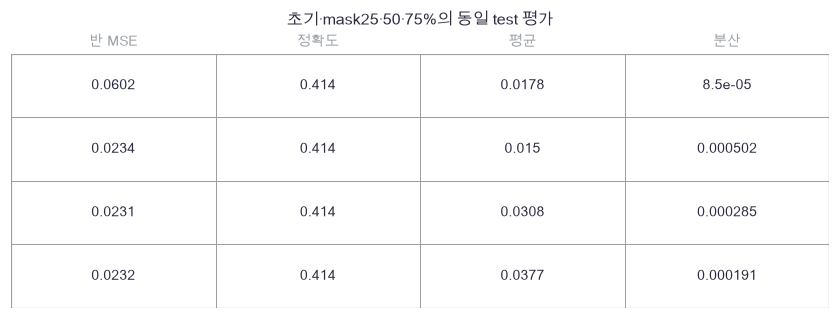

In [42]:
plot_panels([report],['초기·mask25·50·75%의 동일 test 평가'],[['반 MSE','정확도','평균','분산']])

In [43]:
# 쓰는 것: test_mask (5절) · test_x (5절) · unpatchify (1절)
display_id=0
masked_pixels=unpatchify(test_x*(1-test_mask[:,:,None]))[display_id]
reconstructions=[unpatchify(p)[display_id] for p in predictions[1:]]
completed=test_x[display_id:display_id+1]*(1-test_mask[display_id:display_id+1,:,None])+predictions[2][display_id:display_id+1]*test_mask[display_id:display_id+1,:,None]
completed_image=unpatchify(completed)[0]

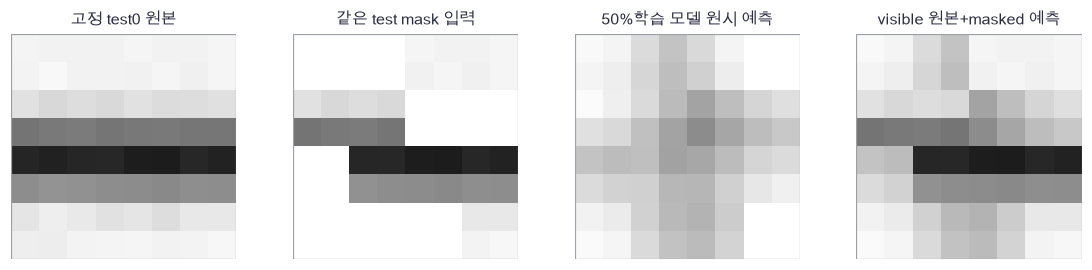

In [44]:
plot_images([test_images[display_id],masked_pixels,reconstructions[1],completed_image],['고정 test0 원본','같은 test mask 입력','50%학습 모델 원시 예측','visible 원본+masked 예측'])

🔍 **확인** · 원시 예측의 visible 위치는 손실로 학습하지 않았습니다. 오른쪽 합성 영상은 보인 화소를 원본으로 채운 것이므로 전체 화소 오차를 모델의 복원 성능이라고 부르면 안 됩니다. 그림의 표시 범위는0–1이며 수치 평가에는 예측을 clip하지 않습니다. 작은 평균 오차와 방향 probe는 서로 다른 정보를 측정합니다. 이 고정 실행에서 학습 반 MSE는 약.0231–.0235로 평균 이미지 기준선.0237에 가깝고, 방향 probe는 초기와 세 조건 모두 약.414입니다. 따라서 유용한 방향 표현을 배웠다는 증거는 얻지 못했습니다. encoder에도 E 위치 정보가 있지만 visible 특징을 하나의 평균 context로 압축하는 제한이 있습니다. decoder 위치 R은 압축에서 사라진 공간 정보를 자동으로 복원하지 못합니다. 위 순열 검산은 원래 위치 ids를 유지한 목록 재정렬이며, 화소의 실제 공간 재배치에 대한 불변성을 뜻하지 않습니다. attention으로 visible 특징들을 연결하거나 위치 조건을 바꾸는 후속 비교는 새 분할·고정 계획으로 수행하세요. 작은 구조와 고정 probe 예산의 한계가 있으며 test 결과를 보고 구조·예산을 다시 고르지는 않습니다.

### ✏️ 연습 5 · 보인 원본과 가린 예측 합치기

그림용 완성 영상 patch를 만드세요. 수치 평가는 masked-only로 따로 합니다.

In [45]:
def exercise_merge_reconstruction(X,prediction,mask):
    """그림용 완성 영상 patch를 만드세요. 수치 평가는 masked-only로 따로 합니다."""

    ### 구현할 내용: 그림용 완성 영상 patch를 만드세요. 수치 평가는 masked-only로 따로 합니다.
    raise NotImplementedError
    return combined

In [46]:
def check_merge_reconstruction(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_array_equal(candidate(np.array([[[1.],[2.]]]),np.array([[[9.],[8.]]]),np.array([[0.,1.]])),[[[1.],[8.]]])  # 검산: 보인1은 원본, 가린2는예측8
    print("연습 5: 독립 기준값과 일치합니다.")

run_check(check_merge_reconstruction,exercise_merge_reconstruction,hint="그림용 완성 영상 patch를 만드세요. 수치 평가는 masked-only로 따로 합니다.")

☐ exercise_merge_reconstruction: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 그림용 완성 영상 patch를 만드세요. 수치 평가는 masked-only로 따로 합니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
combined = X*(1-mask[:,:,None])+prediction*mask[:,:,None]
```

</details>

## ✏️ 끝 연습 · shape와 가림 규약을 바꿉니다

### ✏️ 연습 A · 다른 해상도의 patch 수

높이·너비가 patch의 배수일 때 직사각형 이미지의 patch 수를 구하세요.

In [47]:
def exercise_patch_count(height,width,patch):
    """높이·너비가 patch의 배수일 때 직사각형 이미지의 patch 수를 구하세요."""

    ### 구현할 내용: 높이·너비가 patch의 배수일 때 직사각형 이미지의 patch 수를 구하세요.
    raise NotImplementedError
    return count

In [48]:
def check_patch_count(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_equal(candidate(6,8,2),12)  # 검산: 3×4 patch
    print("연습 A: 독립 기준값과 일치합니다.")

run_check(check_patch_count,exercise_patch_count,hint="높이·너비가 patch의 배수일 때 직사각형 이미지의 patch 수를 구하세요.")

☐ exercise_patch_count: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 높이·너비가 patch의 배수일 때 직사각형 이미지의 patch 수를 구하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
count = (height//patch)*(width//patch)
```

</details>

### ✏️ 연습 B · masked 화소의 미분

mask가 비어 있지 않을 때 반 MSE의 예측 기울기를 계산하세요.

In [49]:
def exercise_pixel_gradient(prediction,target,mask):
    """mask가 비어 있지 않을 때 반 MSE의 예측 기울기를 계산하세요."""
    count = mask.sum()*prediction.shape[-1]
    ### 구현할 내용: mask가 비어 있지 않을 때 반 MSE의 예측 기울기를 계산하세요.
    raise NotImplementedError
    return gradient

In [50]:
def check_pixel_gradient(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[[3.,5.],[9.,9.]]]),np.array([[[1.,1.],[0.,0.]]]),np.array([[1.,0.]])),[[[1.,2.],[0.,0.]]])  # 검산: 두 가린 화소의 분모2
    print("연습 B: 독립 기준값과 일치합니다.")

run_check(check_pixel_gradient,exercise_pixel_gradient,hint="mask가 비어 있지 않을 때 반 MSE의 예측 기울기를 계산하세요.")

☐ exercise_pixel_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: mask가 비어 있지 않을 때 반 MSE의 예측 기울기를 계산하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = (prediction-target)*mask[:,:,None]/count
```

</details>

### ✏️ 연습 C · 공유 mask token의 누적

decoder preactivation의 상류 G에서 mask token 기울기를 더하세요.

In [51]:
def exercise_mask_token_grad(G,mask):
    """decoder preactivation의 상류 G에서 mask token 기울기를 더하세요."""

    ### 구현할 내용: decoder preactivation의 상류 G에서 mask token 기울기를 더하세요.
    raise NotImplementedError
    return gradient

In [52]:
def check_mask_token_grad(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[[1.,2.],[3.,4.]]]),np.array([[0.,1.]])),[3.,4.])  # 검산: 가린 위치의 두 특징만
    print("연습 C: 독립 기준값과 일치합니다.")

run_check(check_mask_token_grad,exercise_mask_token_grad,hint="decoder preactivation의 상류 G에서 mask token 기울기를 더하세요.")

☐ exercise_mask_token_grad: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: decoder preactivation의 상류 G에서 mask token 기울기를 더하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = (G*mask[:,:,None]).sum(axis=(0,1))
```

</details>

### ✏️ 연습 D · 가림 수가 다른 이미지의 평균

이미지별 반 제곱오차 합과 가린 화소 수에서 전역 화소 평균을 계산하세요.

In [53]:
def exercise_unequal_masks(sums,counts):
    """이미지별 반 제곱오차 합과 가린 화소 수에서 전역 화소 평균을 계산하세요."""

    ### 구현할 내용: 이미지별 반 제곱오차 합과 가린 화소 수에서 전역 화소 평균을 계산하세요.
    raise NotImplementedError
    return loss

In [54]:
def check_unequal_masks(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([2.,12.]),np.array([2.,6.])),1.75)  # 검산: (2+12)/(2+6), 이미지평균1.5와 다름
    print("연습 D: 독립 기준값과 일치합니다.")

run_check(check_unequal_masks,exercise_unequal_masks,hint="이미지별 반 제곱오차 합과 가린 화소 수에서 전역 화소 평균을 계산하세요.")

☐ exercise_unequal_masks: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 이미지별 반 제곱오차 합과 가린 화소 수에서 전역 화소 평균을 계산하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
loss = sums.sum()/counts.sum()
```

</details>

### ✏️ 준비도 질문

- **설명:** encoder 입력의 mask와 decoder mask token은 왜 다르며, visible 원본을 채운 그림은 왜 순수 예측이 아닌가요? → 1·2·5절
- **수식:** patch 순서·K평균·masked 화소 분모·scatter 역전파를 쓸 수 있나요? → 1–4절
- **구현:** 가린 입력을 바꿔도 예측이 같음을 확인하고 모든 배열의 미분을 검산할 수 있나요? → 2·4절
- **변형 검산:** 직사각형 해상도·빈 mask·다른 K·이미지별 다른 가림 수의 의미를 확인할 수 있나요? → 1·3절, 연습 A–D

### 📎 원전과 다음 연결

[MAE 원논문, He et al., 2022](https://arxiv.org/abs/2111.06377)은 visible patch만 처리하는 encoder와 가린 화소를 복원하는 decoder를 제안합니다. 여기서는 attention 대신 공유 tanh·평균 context를 쓰며 원논문의 구조·규모·성능을 재현하지 않습니다. 43번은 같은 자료에서 화소 타깃 대신 교사 표현을 맞히는 JEPA식 축소 예제를 다룹니다.